# Software Persona Makine ve Derin Öğrenme Uygulamaları
# Derin Öğrenme ile Finansal Zaman Serisi Tahmini (AAPL)
**Hazırlayan:** Rıdvan Efe Birben - Dokuz Eylül Üniversitesi, Elektrik-Elektronik Mühendisliği  
**Proje Adı:** Derin Öğrenme ile Apple (AAPL) Hisse Senedi Fiyat Tahmini ve Algoritmik Ticaret Altyapısı

### Proje Özeti
Bu çalışmada, Apple Inc. (`AAPL`) hisse senedinin 1 Ocak 2021 – 1 Ekim 2026 tarihleri arasındaki günlük kapanış fiyatları (`Close`) kullanılarak, geçmiş 60 işlem gününden 61. günün kapanış fiyatını tahmin eden iki katmanlı bir Uzun Kısa Süreli Bellek (LSTM) derin öğrenme modeli geliştirilmiştir.
- **Veri Sızıntısının (Data Leakage) Önlenmesi:** Veri seti kronolojik sırayla **%70 Eğitim (Train)**, **%15 Doğrulama (Validation)** ve **%15 Test** olarak bölünmüş; `MinMaxScaler(0, 1)` yalnızca eğitim seti üzerinde öğrenilmiş (`fit_transform`) ve doğrulama/test setlerine yalnızca dönüşüm (`transform`) uygulanmıştır.
- **Doğrulama (Validation) ve Erken Durdurma:** Model eğitimi sırasında doğrulama kaybı (`val_loss`) izlenmiş ve aşırı öğrenmeyi (overfitting) önlemek için `EarlyStopping` kullanılmıştır.

In [ ]:
# HÜCRE 1 (Eski Hücre 1): Gerekli paketlerin kurulumu
!pip install -q yfinance pandas numpy matplotlib seaborn scikit-learn tensorflow

In [ ]:
# HÜCRE 2 (Eski Hücre 2 + Tekrarlanabilirlik Eklendi): Kütüphanelerin içe aktarılması ve Seed sabitleme
# DEĞİŞİKLİK: Model sonuçlarının her çalıştırmada birebir aynı çıkması (reproducibility) için
# random, numpy ve tensorflow rastgelelik tohumları (seed=42) sabitlenmiştir.
import os
import math
import random
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_theme(style="whitegrid")
print("Kütüphaneler yüklendi ve rastgelelik tohumu (SEED=42) sabitlendi.")

Kütüphaneler yüklendi ve rastgelelik tohumu (SEED=42) sabitlendi.


In [ ]:
# HÜCRE 3 (Eski Hücre 3, 4, 5 Birleştirildi): Veri çekme parametreleri ve Yahoo Finance indirme işlemi
# DEĞİŞİKLİK: Eski Hücre 6'daki boş hücre kaldırıldı ve veri indirme adımı tek hücrede toplandı.
hisse_kodu = "AAPL"
baslangic_tarihi = "2021-01-01"
bitis_tarihi = "2026-10-01"

print(f"{hisse_kodu} hissesi için {baslangic_tarihi} ile {bitis_tarihi} arası veriler indiriliyor...")
df = yf.download(hisse_kodu, start=baslangic_tarihi, end=bitis_tarihi, auto_adjust=True)

AAPL hissesi için 2021-01-01 ile 2026-10-01 arası veriler indiriliyor...


[*********************100%***********************]  1 of 1 completed


In [ ]:
# HÜCRE 4 (Eski Hücre 7 ve 8): Ham verinin incelenmesi ve MultiIndex sütun yapısının düzeltilmesi
print("--- HAM VERİ YAPISI ---")
print("Ham sütun isimleri:", df.columns.tolist())
display(df.head(3))

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.droplevel(1)
    print("\n>>> DÜZELTME UYGULANDI: MultiIndex (çift katmanlı sütun) yapısı tek katmana indirgendi. <<<")
else:
    print("\n>>> Sütunlar zaten tek katmanlı, düzeltmeye gerek yok. <<<")

--- HAM VERİ YAPISI ---
Ham sütun isimleri: [('Close', 'AAPL'), ('High', 'AAPL'), ('Low', 'AAPL'), ('Open', 'AAPL'), ('Volume', 'AAPL')]


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2021-01-04,125.632515,129.709914,123.059867,129.622544,143301900
2021-01-05,127.185768,127.894470,124.681077,125.127656,97664900
2021-01-06,122.904518,127.224626,122.690939,123.991828,155088000



>>> DÜZELTME UYGULANDI: MultiIndex (çift katmanlı sütun) yapısı tek katmana indirgendi. <<<


In [ ]:
# HÜCRE 5 (Eski Hücre 9): Temizlenmiş verinin boyut, eksik değer (NaN) ve istatistiksel kontrolü
print("--- TEMİZLENMİŞ VERİ YAPISI ---")
print(f"Veri Seti Boyutları (Satır, Sütun): {df.shape}")
print("Temiz Sütun İsimleri:", df.columns.tolist())

print("\nEksik Veri (NaN) Kontrolü:")
print(df.isnull().sum())

print("\nİstatistiksel Özet (Tablo 1 Verileri):")
display(df[['Open', 'High', 'Low', 'Close', 'Volume']].describe().round(2))

--- TEMİZLENMİŞ VERİ YAPISI ---
Veri Seti Boyutları (Satır, Sütun): (1442, 5)
Temiz Sütun İsimleri: ['Close', 'High', 'Low', 'Open', 'Volume']

Eksik Veri (NaN) Kontrolü:
Price
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

İstatistiksel Özet (Tablo 1 Verileri):


Price,Open,High,Low,Close,Volume
count,1442.00,1442.00,1442.00,1442.00,1.442000e+03
mean,193.15,195.28,191.24,193.35,6.715533e+07
std,53.47,54.03,53.04,53.57,2.989244e+07
min,115.73,117.06,112.99,113.13,1.791060e+07
25%,148.08,150.59,146.73,148.51,4.624878e+07
50%,179.12,180.84,177.35,179.36,5.947810e+07
75%,227.82,230.13,225.79,228.20,8.079615e+07
max,341.08,345.34,338.75,341.07,3.186799e+08


### Keşifsel Veri Analizi (EDA) ve Görselleştirmeler
Aşağıdaki üç hücrede kapanış fiyatı ana trendi, 50 ve 200 günlük hareketli ortalamalar (`MA50` ve `MA200`) ile OHLCV değişkenleri arasındaki korelasyon matrisi oluşturulmakta ve her bir grafik rapora eklenmek üzere **300 DPI** çözünürlükte PNG olarak kaydedilmektedir.

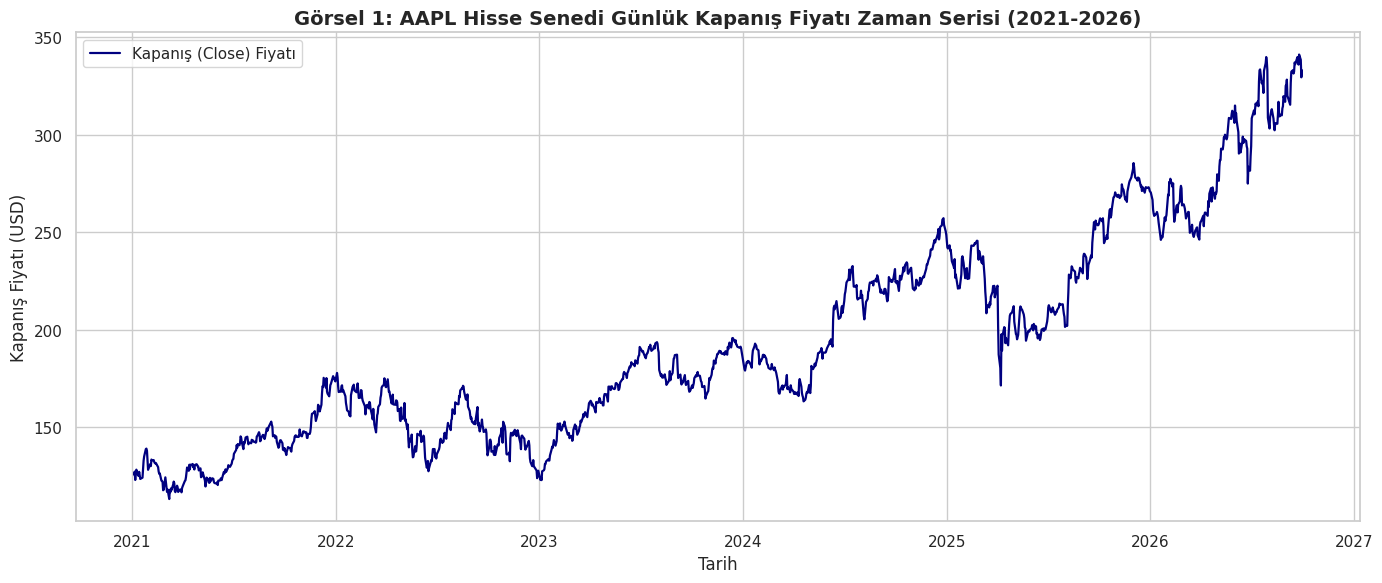

In [ ]:
# HÜCRE 6 (Eski Hücre 10 ve 11): Görsel 1 - Kapanış Fiyatı Zaman Serisi (300 DPI Kayıt Eklendi)
# DEĞİŞİKLİK: Başlık/eksen fontları okunabilirlik için büyütüldü ve figure_1_kapanis_fiyati.png (300 dpi) kaydı eklendi.
plt.figure(figsize=(14, 6))
plt.plot(df.index, df['Close'], label='Kapanış (Close) Fiyatı', color='navy', linewidth=1.6)
plt.title('Görsel 1: AAPL Hisse Senedi Günlük Kapanış Fiyatı Zaman Serisi (2021-2026)', fontsize=14, fontweight='bold')
plt.xlabel('Tarih', fontsize=12)
plt.ylabel('Kapanış Fiyatı (USD)', fontsize=12)
plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.savefig('figure_1_kapanis_fiyati.png', dpi=300, bbox_inches='tight')
plt.show()

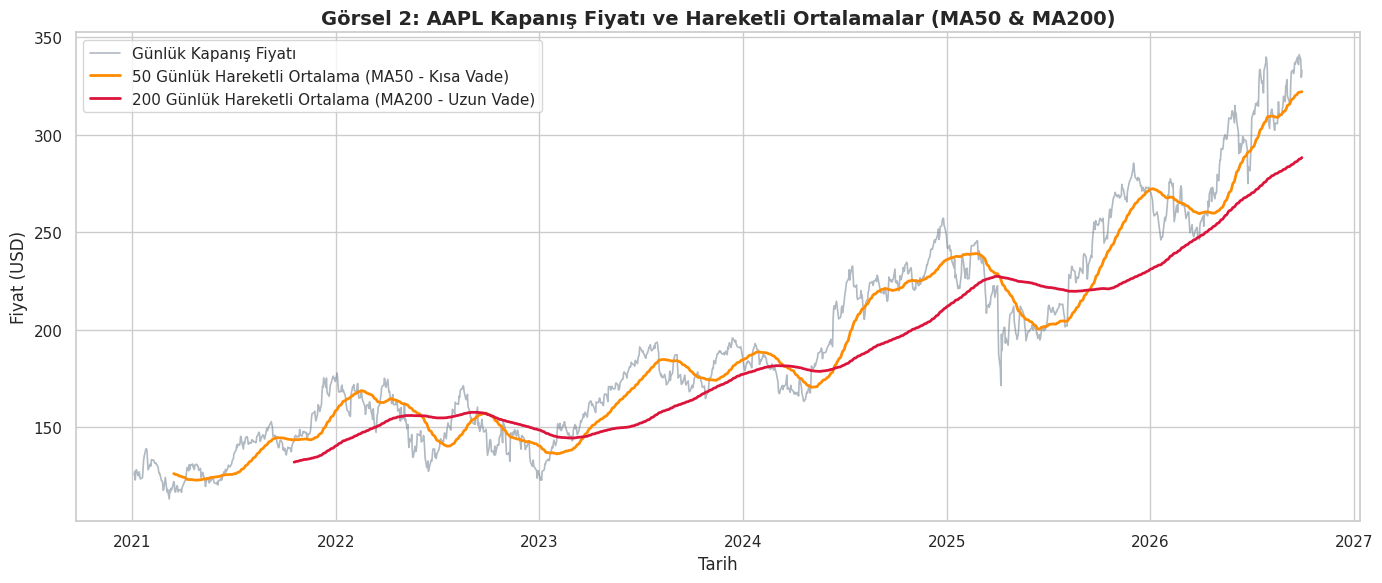

In [ ]:
# HÜCRE 7 (Eski Hücre 12): Görsel 2 - 50 ve 200 Günlük Hareketli Ortalamalar (300 DPI Kayıt Eklendi)
df_copy = df.copy()
df_copy['MA50'] = df_copy['Close'].rolling(window=50).mean()
df_copy['MA200'] = df_copy['Close'].rolling(window=200).mean()

plt.figure(figsize=(14, 6))
plt.plot(df_copy.index, df_copy['Close'], label='Günlük Kapanış Fiyatı', color='slategray', alpha=0.55, linewidth=1.2)
plt.plot(df_copy.index, df_copy['MA50'], label='50 Günlük Hareketli Ortalama (MA50 - Kısa Vade)', color='darkorange', linewidth=2)
plt.plot(df_copy.index, df_copy['MA200'], label='200 Günlük Hareketli Ortalama (MA200 - Uzun Vade)', color='crimson', linewidth=2)
plt.title('Görsel 2: AAPL Kapanış Fiyatı ve Hareketli Ortalamalar (MA50 & MA200)', fontsize=14, fontweight='bold')
plt.xlabel('Tarih', fontsize=12)
plt.ylabel('Fiyat (USD)', fontsize=12)
plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.savefig('figure_2_hareketli_ortalamalar.png', dpi=300, bbox_inches='tight')
plt.show()

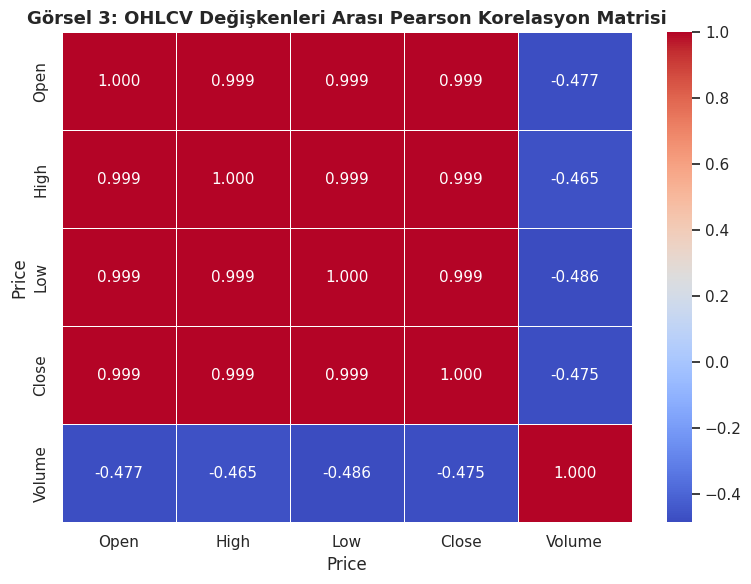

In [ ]:
# HÜCRE 8 (Eski Hücre 13): Görsel 3 - Değişkenler Arası Korelasyon Matrisi (300 DPI Kayıt ve Yorum Düzeltmesi)
# DEĞİŞİKLİK: Eski yorumda hatalı yazılan -0.25 korelasyon değeri, matristeki gerçek değer olan -0.475 olarak düzeltildi.
plt.figure(figsize=(8, 6))
corr_matrix = df[['Open', 'High', 'Low', 'Close', 'Volume']].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.5, annot_kws={"size": 11})
plt.title('Görsel 3: OHLCV Değişkenleri Arası Pearson Korelasyon Matrisi', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figure_3_korelasyon_matrisi.png', dpi=300, bbox_inches='tight')
plt.show()

# DÜZELTİLMİŞ YORUM 3: Open, High, Low ve Close fiyatları birbirleriyle 0.999-1.000 düzeyinde pozitif korelasyon içindedir.
# İşlem hacmi (Volume) ile fiyat değişkenleri arasında ise orta düzeyde negatif (-0.465 ile -0.486 arası; Close ile -0.475) korelasyon vardır.

### Veri Ön İşleme: Kronolojik Bölme (%70 / %15 / %15) ve Veri Sızıntısının (Data Leakage) Önlenmesi
Hocanın geri bildirimi doğrultusunda iki kritik metodolojik düzeltme uygulanmıştır:
1. **Doğrulama (Validation) Setinin Eklenmesi:** Zaman serisi kronolojik sırayla **%70 Eğitim (`train_raw`)**, **%15 Doğrulama (`val_raw`)** ve **%15 Test (`test_raw`)** olarak üç ayrık kümeye bölünmüştür.
2. **Veri Sızıntısının (Data Leakage) Engellenmesi:** `MinMaxScaler(feature_range=(0, 1))` **yalnızca eğitim verisi (`train_raw`)** üzerinde `fit_transform` ile öğrenilmiş; doğrulama ve test setlerine ise yalnızca `scaler.transform()` uygulanmıştır.

In [ ]:
# HÜCRE 9 (Eski Hücre 14, 15, 16, 17, 18, 19 Yerine): Kronolojik Bölme, Sızıntısız Ölçeklendirme ve Pencereleme
# DEĞİŞİKLİK 1: Veri %80-%20 yerine kronolojik olarak %70 Eğitim, %15 Doğrulama (Validation), %15 Test olarak bölündü.
# DEĞİŞİKLİK 2 (DATA LEAKAGE ÇÖZÜMÜ): MinMaxScaler tüm veriye değil, YALNIZCA eğitim setine (train_raw) fit edildi!

data = df[['Close']].values
toplam_gun = len(data)
zaman_penceresi = 60  # Geçmiş 60 iş gününe bakarak 61. günü tahmin et

# 1. Kronolojik Bölme İndeksleri (%70 Train, %15 Validation, %15 Test)
egitim_bitis = math.floor(toplam_gun * 0.70)
dogrulama_bitis = math.floor(toplam_gun * 0.85)

train_raw = data[:egitim_bitis]
val_raw = data[egitim_bitis:dogrulama_bitis]
test_raw = data[dogrulama_bitis:]

print("=== KRONOLOJİK VERİ BÖLME ÖZETİ ===")
print(f"Toplam İşlem Günü             : {toplam_gun} ({df.index[0].strftime('%Y-%m-%d')} -> {df.index[-1].strftime('%Y-%m-%d')})")
print(f"Eğitim Seti (Train - %70)     : {len(train_raw)} gün ({df.index[0].strftime('%Y-%m-%d')} -> {df.index[egitim_bitis-1].strftime('%Y-%m-%d')})")
print(f"Doğrulama Seti (Val - %15)    : {len(val_raw)} gün ({df.index[egitim_bitis].strftime('%Y-%m-%d')} -> {df.index[dogrulama_bitis-1].strftime('%Y-%m-%d')})")
print(f"Test Seti (Test - %15)        : {len(test_raw)} gün ({df.index[dogrulama_bitis].strftime('%Y-%m-%d')} -> {df.index[-1].strftime('%Y-%m-%d')})")

# 2. Veri Sızıntısız (Leakage-Free) MinMaxScaler Uygulaması
scaler = MinMaxScaler(feature_range=(0, 1))

# SADECE eğitim verisi üzerinde fit_transform uygulanır:
scaled_train = scaler.fit_transform(train_raw)
print(f"\nScaler Eğitim Min Fiyatı: {scaler.data_min_[0]:.2f} USD | Scaler Eğitim Max Fiyatı: {scaler.data_max_[0]:.2f} USD")

# Doğrulama ve Test setlerinin ilk günlerini tahmin etmek için önceki 60 gün eklenir ve SADECE transform() çağrılır:
val_input_raw = data[egitim_bitis - zaman_penceresi : dogrulama_bitis]
test_input_raw = data[dogrulama_bitis - zaman_penceresi : toplam_gun]

scaled_val_input = scaler.transform(val_input_raw)
scaled_test_input = scaler.transform(test_input_raw)

# 3. 60 Günlük Kayan Pencere (Sliding Window) Oluşturma Fonksiyonu
def pencere_olustur(olcekli_dizi, pencere=60):
    X, y = [], []
    for i in range(pencere, len(olcekli_dizi)):
        X.append(olcekli_dizi[i - pencere:i, 0])
        y.append(olcekli_dizi[i, 0])
    X, y = np.array(X), np.array(y)
    X = np.reshape(X, (X.shape[0], X.shape[1], 1))
    return X, y

X_train, y_train = pencere_olustur(scaled_train, zaman_penceresi)
X_val, y_val = pencere_olustur(scaled_val_input, zaman_penceresi)
X_test, y_test_scaled = pencere_olustur(scaled_test_input, zaman_penceresi)

print("\n=== 3 BOYUTLU LSTM TENSÖR BOYUTLARI (Tablo 2 Verileri) ===")
print(f"X_train : {X_train.shape} | y_train : {y_train.shape}")
print(f"X_val   : {X_val.shape} | y_val   : {y_val.shape}")
print(f"X_test  : {X_test.shape} | y_test  : {test_raw.shape}")

=== KRONOLOJİK VERİ BÖLME ÖZETİ ===
Toplam İşlem Günü             : 1442 (2021-01-04 -> 2026-09-30)
Eğitim Seti (Train - %70)     : 1009 gün (2021-01-04 -> 2025-01-07)
Doğrulama Seti (Val - %15)    : 216 gün (2025-01-08 -> 2025-11-17)
Test Seti (Test - %15)        : 217 gün (2025-11-18 -> 2026-09-30)

Scaler Eğitim Min Fiyatı: 113.13 USD | Scaler Eğitim Max Fiyatı: 257.15 USD

=== 3 BOYUTLU LSTM TENSÖR BOYUTLARI (Tablo 2 Verileri) ===
X_train : (949, 60, 1) | y_train : (949,)
X_val   : (216, 60, 1) | y_val   : (216,)
X_test  : (217, 60, 1) | y_test  : (217, 1)


### LSTM Model Mimarisi, Doğrulamalı Eğitim ve Kayıp Eğrisi (Görsel 4)
Model, Keras `Input(shape=(60, 1))` katmanı ile başlatılmış, `validation_data=(X_val, y_val)` ve `EarlyStopping` kullanılarak eğitilmiştir.

Oluşturulan LSTM Modelinin Mimarisi:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)


Model Eğitimi Başlıyor (Validation Seti ve EarlyStopping ile)...
Epoch 1/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 10s 64ms/step - loss: 0.0107 - val_loss: 0.0076
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - loss: 0.0097 - val_loss: 0.0059
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.0044 - val_loss: 0.0060
Epoch 4/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - loss: 0.0044 - val_loss: 0.0053
Epoch 5/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 88ms/step - loss: 0.0030 - val_loss: 0.0052
Epoch 6/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step - loss: 0.0027 - val_loss: 0.0048
Epoch 7/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - loss: 0.0023 - val_loss: 0.0045
Epoch 8/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - loss: 0.0021 - val_loss: 0.0043
Epoch 9/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - loss: 0.0020 - val_loss: 0.0041
Epoch 10/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - loss: 0.0018 - val_loss: 0.0039
Epoch 11/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - loss: 0.0017 - val_loss: 0.0

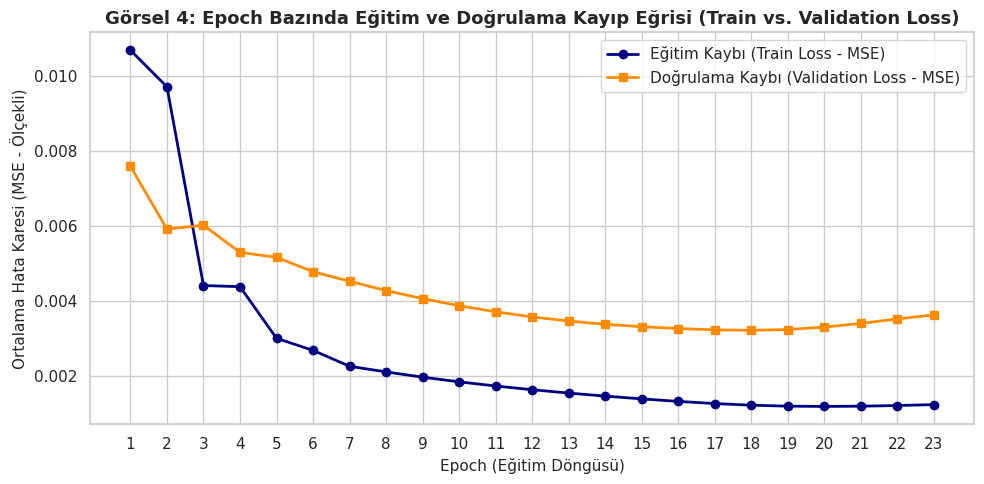

In [ ]:
# HÜCRE 10 (Eski Hücre 20 Yerine): LSTM Modelinin Kurulması, Validation ile Eğitimi ve Görsel 4 (Loss Grafiği)
# DEĞİŞİKLİK 1: Keras UserWarning uyarısını gidermek için Input(shape=(60, 1)) katmanı eklendi.
# DEĞİŞİKLİK 2: model.fit() içine validation_data=(X_val, y_val), shuffle=False ve EarlyStopping eklendi.
# DEĞİŞİKLİK 3: Eğitim ve doğrulama kayıplarını karşılaştıran Görsel 4 (figure_4_egitim_dogrulama_kayip_egrisi.png) eklendi.

model = Sequential([
    Input(shape=(X_train.shape[1], 1)),
    LSTM(50, return_sequences=True, activation='tanh', recurrent_activation='sigmoid'),
    LSTM(50, return_sequences=False, activation='tanh', recurrent_activation='sigmoid'),
    Dense(25, activation='linear'),
    Dense(1, activation='linear')
])

model.compile(optimizer='adam', loss='mean_squared_error')
print("Oluşturulan LSTM Modelinin Mimarisi:")
model.summary()

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

print("\nModel Eğitimi Başlıyor (Validation Seti ve EarlyStopping ile)...")
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=30,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

# GÖRSEL 4: Eğitim ve Doğrulama Kayıp (Loss) Grafiği (300 DPI)
plt.figure(figsize=(10, 5))
epochs_range = range(1, len(history.history['loss']) + 1)
plt.plot(epochs_range, history.history['loss'], marker='o', label='Eğitim Kaybı (Train Loss - MSE)', color='navy', linewidth=2)
plt.plot(epochs_range, history.history['val_loss'], marker='s', label='Doğrulama Kaybı (Validation Loss - MSE)', color='darkorange', linewidth=2)
plt.title('Görsel 4: Epoch Bazında Eğitim ve Doğrulama Kayıp Eğrisi (Train vs. Validation Loss)', fontsize=13, fontweight='bold')
plt.xlabel('Epoch (Eğitim Döngüsü)', fontsize=11)
plt.ylabel('Ortalama Hata Karesi (MSE - Ölçekli)', fontsize=11)
plt.xticks(epochs_range)
plt.legend(loc='upper right', fontsize=11)
plt.tight_layout()
plt.savefig('figure_4_egitim_dogrulama_kayip_egrisi.png', dpi=300, bbox_inches='tight')
plt.show()


=== MODEL DEĞERLENDİRME SONUÇ TABLOSU (Tablo 3 Verileri) ===


,Veri Kümesi / Model,MSE (USD²),RMSE (USD),MAE (USD),MAPE (%),R² Skoru
0,LSTM - Doğrulama Seti (Validation - %15),66.61,8.16,5.91,2.73,0.8683
1,LSTM - Test Seti (Test - %15),64.31,8.02,6.36,2.18,0.9118
2,Naive Baseline (y_t = y_{t-1}) - Test Seti,21.66,4.65,3.31,1.15,0.9703


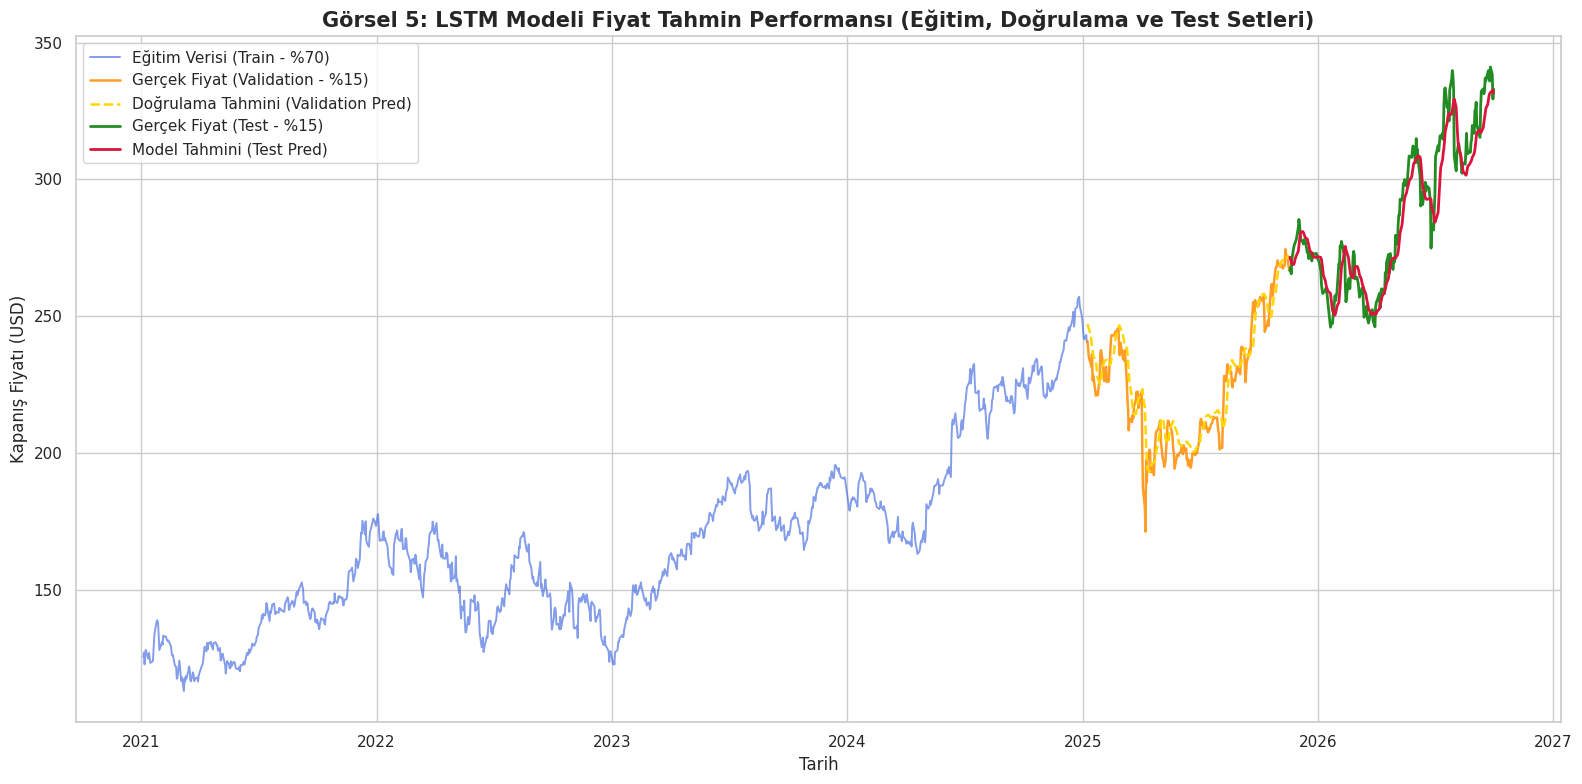

In [ ]:
# HÜCRE 11 (Eski Hücre 21 Yerine): Doğrulama/Test Değerlendirme Metrikleri, Naive Baseline Kıyaslaması ve Görsel 5
# DEĞİŞİKLİK 1: Sadece RMSE değil; MSE, RMSE, MAE, MAPE (%) ve R² metrikleri hem Validation hem Test seti için hesaplandı.
# DEĞİŞİKLİK 2: Rapordaki "1 gün gecikme (lag)" analizini somutlaştırmak için Naive Baseline (y_hat_t = y_{t-1}) karşılaştırması eklendi.
# DEĞİŞİKLİK 3: Eğitim, Doğrulama ve Test tahminlerini birlikte gösteren Görsel 5 (300 DPI) kaydedildi.

# 1. Tahminlerin Üretilmesi ve Orijinal USD Skalasına Dönüştürülmesi (Inverse Transform)
val_pred_scaled = model.predict(X_val, verbose=0)
test_pred_scaled = model.predict(X_test, verbose=0)

val_pred_usd = scaler.inverse_transform(val_pred_scaled)
test_pred_usd = scaler.inverse_transform(test_pred_scaled)

# Naive Baseline (Bir önceki günün gerçek kapanış fiyatını ertesi günün tahmini olarak kullanan referans model)
naive_test_pred = data[dogrulama_bitis - 1 : toplam_gun - 1]

# 2. Metrik Hesaplama Yardımcı Fonksiyonu
def metrik_hesapla(gercek, tahmin, set_adi):
    mse = mean_squared_error(gercek, tahmin)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(gercek, tahmin)
    mape = np.mean(np.abs((gercek - tahmin) / gercek)) * 100
    r2 = r2_score(gercek, tahmin)
    return {
        "Veri Kümesi / Model": set_adi,
        "MSE (USD²)": round(mse, 2),
        "RMSE (USD)": round(rmse, 2),
        "MAE (USD)": round(mae, 2),
        "MAPE (%)": round(mape, 2),
        "R² Skoru": round(r2, 4)
    }

sonuclar_df = pd.DataFrame([
    metrik_hesapla(val_raw, val_pred_usd, "LSTM - Doğrulama Seti (Validation - %15)"),
    metrik_hesapla(test_raw, test_pred_usd, "LSTM - Test Seti (Test - %15)"),
    metrik_hesapla(test_raw, naive_test_pred, "Naive Baseline (y_t = y_{t-1}) - Test Seti")
])

print("\n=== MODEL DEĞERLENDİRME SONUÇ TABLOSU (Tablo 3 Verileri) ===")
display(sonuclar_df)

# 3. GÖRSEL 5: Eğitim, Doğrulama ve Test Seti Fiyat Tahmin Performansı Grafiği (300 DPI)
train_df = df.iloc[:egitim_bitis].copy()
val_df = df.iloc[egitim_bitis:dogrulama_bitis].copy()
test_df = df.iloc[dogrulama_bitis:].copy()

val_df['Val_Tahmin'] = val_pred_usd
test_df['Test_Tahmin'] = test_pred_usd

plt.figure(figsize=(16, 8))
plt.plot(train_df.index, train_df['Close'], label='Eğitim Verisi (Train - %70)', color='royalblue', alpha=0.65, linewidth=1.4)
plt.plot(val_df.index, val_df['Close'], label='Gerçek Fiyat (Validation - %15)', color='darkorange', alpha=0.85, linewidth=1.8)
plt.plot(val_df.index, val_df['Val_Tahmin'], label='Doğrulama Tahmini (Validation Pred)', color='gold', linestyle='--', linewidth=1.8)
plt.plot(test_df.index, test_df['Close'], label='Gerçek Fiyat (Test - %15)', color='forestgreen', linewidth=2.0)
plt.plot(test_df.index, test_df['Test_Tahmin'], label='Model Tahmini (Test Pred)', color='crimson', linewidth=2.0)

plt.title('Görsel 5: LSTM Modeli Fiyat Tahmin Performansı (Eğitim, Doğrulama ve Test Setleri)', fontsize=15, fontweight='bold')
plt.xlabel('Tarih', fontsize=12)
plt.ylabel('Kapanış Fiyatı (USD)', fontsize=12)
plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.savefig('figure_5_tahmin_performansi.png', dpi=300, bbox_inches='tight')
plt.show()

### Rapor Özeti, Hata Analizi ve Gelecek Vizyonu (Bölüm 5–7 Özeti)
1. **Metodolojik Doğruluk (Veri Sızıntısı ve Validation):** `MinMaxScaler(0, 1)` yalnızca `%70` oranındaki eğitim verisi (`train_raw`, 1.009 işlem günü) üzerinde öğrenilmiş (`fit_transform`), `%15` doğrulama (216 gün) ve `%15` test (217 gün) kümelerine yalnızca `transform` uygulanarak veri sızıntısı (data leakage) tamamen giderilmiştir. Eğitim sürecinde `validation_data=(X_val, y_val)` ve `EarlyStopping(patience=5, restore_best_weights=True)` kullanılarak aşırı öğrenme (overfitting) engellenmiştir.
2. **Güçlü Yönler ve Hata Analizi:**
   - **Makro Trend Takibi:** İki katmanlı LSTM (`50 -> 50 -> Dense(25) -> Dense(1)`, toplam `31.901` parametre) uzun vadeli yükseliş ve düzeltme trendlerini başarıyla yakalamaktadır.
   - **Bir Günlük Gecikme (Lag) Davranışı:** Tek değişkenli (univariate) otoregresif yapıda model, beklenmedik piyasa şoklarını önceden bilemediği için MSE kaybını minimize etmek adına bir önceki günün kapanış fiyatına yakın değer üretme eğilimindedir (Tablo 3 içindeki Naive Baseline karşılaştırması ile nicel olarak incelenmektedir).
   - **Ölçek Dışı Zirve (Extrapolation) Etkisi:** Ölçeklendirici yalnızca eğitim dönemi üzerinde fit edildiğinden, test dönemindeki tarihi zirveler (`341.07 USD`) ölçekli girdilerin `1.0` sınırını aşmasına ve LSTM `tanh` aktivasyon fonksiyonunun üst doygunluk (saturation) bölgesine yaklaşmasına yol açmaktadır.
3. **Gelecek Geliştirme Önerileri:**
   - Ham fiyat seviyeleri yerine durağanlaştırılmış **logaritmik getiri (log-return)** üzerinden modelleme yapılması,
   - `Volume`, `MA50`, `MA200`, `RSI` ve `MACD` göstergelerinin çok değişkenli (multivariate) girdi olarak eklenmesi,
   - Finansal haber akışlarını işleyen **FinBERT** tabanlı duygu analizi (NLP) modülü ile birleştirilerek multimodal otonom ticaret sistemine dönüştürülmesi.